In [24]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        count += 1
        if count == 10:
            break
    if count == 10:
        break
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# NOTE: this notebook runs with Internet OFF (required for competition
# submission). kagglehub.dataset_download() requires internet and is not
# used anywhere in this notebook, so it has been removed rather than left
# commented out -- competition/dataset inputs are already attached under
# /kaggle/input and read directly from disk below, no network calls needed.

/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/sample_submission.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/test.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series/1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.43758349334868121588037306541272735960.dcm
/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series/1.2.826.0.1.3680043.8.498.10062861783145312629332250977456991776/1.2.826.0.1.3680043.8.498.10818107180155454609278933308651876447/1.2.826.0.1.3680043.8.498.98300178100494838040275925015059424504.dcm
/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series/1.2.826.0.1.3680043.

In [25]:
# Internet is OFF for this notebook (required for competition submission),
# so no pip installs can run here -- any `pip install` cell would just hang
# or fail with a network error on a committed/submitted run.
#
# pydicom and albumentations are present in the base kaggle/python Docker
# image already, so nothing needs installing for them. langdetect is NOT
# guaranteed to be present (confirmed missing on this environment) -- it's
# only used for optional EDA (language breakdown), not the actual pseudo-
# labeling pipeline, so it's made optional below rather than required.
# If you ever DO need a package that's genuinely missing and load-bearing
# while offline, the only way is to attach a Kaggle Dataset containing the
# pre-downloaded .whl file(s) and install with
# `pip install --no-index --find-links=/kaggle/input/<your-wheels-dataset> <package>`.
#
# The preflight check in the next cell verifies everything actually used
# below imports cleanly, so a missing package fails fast and loudly here
# instead of mid-run, 5+ minutes into training.

In [26]:
import os
import glob
import math
import shutil
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pydicom
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import multilabel_confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
import torchvision.transforms.functional as TF

# transformers/BitsAndBytesConfig import removed: Phase 1 pseudo-labeling is
# now rule-based (see the keyword/negation matcher cell), so nothing in this
# notebook calls a HuggingFace .from_pretrained() anymore -- keeping that
# import around was dead weight and, if it ever WAS exercised, would try to
# hit the Hub over the network, which fails immediately with internet off.

In [ ]:
# --- Offline preflight check -------------------------------------------
# With internet off, a missing package surfaces as a plain ImportError
# wherever it's first used -- possibly 5-10 minutes into a run, after DICOM
# loading or training has already started. Check everything this notebook
# actually needs, up front, so a missing package fails immediately with a
# clear message instead of silently burning GPU time first.
_required_offline = ["pydicom", "cv2", "albumentations", "seaborn", "sklearn", "tqdm"]  # langdetect excluded: optional/diagnostic only, see cell below
_missing = []
import importlib
for _pkg in _required_offline:
    try:
        importlib.import_module(_pkg)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(
        f"Missing packages with internet OFF: {_missing}. These need to "
        f"already be in the base kaggle/python image, or attached as a "
        f"Kaggle Dataset of prebuilt wheels and installed with "
        f"`pip install --no-index --find-links=/kaggle/input/<wheels-dataset> <package>`. "
        f"A plain `pip install` will not work here since internet is off."
    )
print("Offline preflight OK -- all required packages import cleanly.")

In [27]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Phase 1 execution device: {device}")

if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()


Phase 1 execution device: cuda
Active GPU: Tesla T4


In [28]:
comp_dir = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
train_data_csv = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv")
train_series_csv = pd.read_csv("/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv" )
train_series = "/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series" 
LABEL_COLS = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture',
]


In [29]:
from pathlib import Path
import pandas as pd
import pydicom


def inspect_dicom(file_path):
    try:
        # Read header only without loading full pixel array (much faster)
        dcm = pydicom.dcmread(file_path, stop_before_pixels=True)
        return {
            "file_name": file_path.name,
            "PatientID": getattr(dcm, "PatientID", "N/A"),
            "Modality": getattr(dcm, "Modality", "N/A"),
            "Rows": getattr(dcm, "Rows", "N/A"),
            "Columns": getattr(dcm, "Columns", "N/A"),
            "SliceThickness": getattr(dcm, "SliceThickness", "N/A"),
        }
    except Exception as e:
        return {"file_name": file_path.name, "error": str(e)}

folder_path = Path(train_series)

if not folder_path.exists():
    print("Path does not exist! Available folders in /kaggle/input:")
    print(list(Path("/kaggle/input").glob("*")))
else:
    dicom_files = []
    for file_path in folder_path.rglob("*.dcm"):
        if file_path.is_file():
            dicom_files.append(file_path)
            if len(dicom_files) == 10:
                break

    if not dicom_files:
        for file_path in folder_path.rglob("*"):
            if file_path.is_file():
                dicom_files.append(file_path)
                if len(dicom_files) == 10:
                    break

    if dicom_files:
        df_metadata = pd.DataFrame([inspect_dicom(f) for f in dicom_files])
        print(df_metadata)
    else:
        print("No files found inside the specified folder.")



                                           file_name     PatientID Modality  \
0  1.2.826.0.1.3680043.8.498.12486678153168904030...  2272a219-39f       MR   
1  1.2.826.0.1.3680043.8.498.86700687663805155070...  2272a219-39f       MR   
2  1.2.826.0.1.3680043.8.498.40362622123295797247...  2272a219-39f       MR   
3  1.2.826.0.1.3680043.8.498.22606964411658655718...  2272a219-39f       MR   
4  1.2.826.0.1.3680043.8.498.47226698003996911677...  2272a219-39f       MR   
5  1.2.826.0.1.3680043.8.498.41029266142968958477...  2272a219-39f       MR   
6  1.2.826.0.1.3680043.8.498.11454956388719760100...  2272a219-39f       MR   
7  1.2.826.0.1.3680043.8.498.10719509394839994049...  2272a219-39f       MR   
8  1.2.826.0.1.3680043.8.498.16426352596070175970...  2272a219-39f       MR   
9  1.2.826.0.1.3680043.8.498.37555643084024702418...  2272a219-39f       MR   

   Rows  Columns  SliceThickness  
0   640      640             0.9  
1   640      640             0.9  
2   640      640         

---label Sparsity ---
Total Studies: 4407
Expert Labeled: 58 (1.32%)
Unlabeled (Report Only): 4349 (98.68%)



(np.float64(-1.099999887184286),
 np.float64(1.0999999785771886),
 np.float64(-1.0999999468403752),
 np.float64(1.099999996069472))

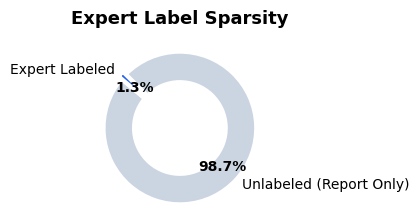

In [30]:
expert_labeled = train_data_csv[LABEL_COLS].notnull().any(axis=1)
labeled_count = expert_labeled.sum()
unlabeled_count = (~expert_labeled).sum()

print(f"---label Sparsity ---")
print(f"Total Studies: {len(train_data_csv)}")
print(f"Expert Labeled: {labeled_count} ({expert_labeled.mean()*100:.2f}%)")
print(f"Unlabeled (Report Only): {unlabeled_count} ({(1-expert_labeled.mean())*100:.2f}%)\n")

#DONUT CHART
colors = ['#cbd5e1', '#2563eb']  

ax1 = plt.subplot(2, 2, 1)
wedges, texts, autotexts = ax1.pie(
    [unlabeled_count, labeled_count],
    labels=['Unlabeled (Report Only)', 'Expert Labeled'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=(0, 0.05),
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=3)  # Donut ring + clean white borders
)

# Enhance inner percentage label typography
plt.setp(autotexts, size=10, weight="bold", color="black")
plt.setp(texts, size=10)

ax1.set_title('Expert Label Sparsity', fontsize=13, fontweight='bold', pad=15)
ax1.axis('equal') 

In [31]:
print(train_data_csv)
print(train_series_csv)

                                       StudyInstanceUID  \
0     1.2.826.0.1.3680043.8.498.10004873229099053869...   
1     1.2.826.0.1.3680043.8.498.10004945927472656027...   
2     1.2.826.0.1.3680043.8.498.10009278692606631573...   
3     1.2.826.0.1.3680043.8.498.10009639203170750274...   
4     1.2.826.0.1.3680043.8.498.10013663742400736029...   
...                                                 ...   
4402  1.2.826.0.1.3680043.8.498.99880021280666757817...   
4403  1.2.826.0.1.3680043.8.498.99881620336512626242...   
4404  1.2.826.0.1.3680043.8.498.99926624968240681772...   
4405  1.2.826.0.1.3680043.8.498.99939100657291954890...   
4406  1.2.826.0.1.3680043.8.498.99957611207313098696...   

                                                 Report  ACL  MCL  \
0     Técnica: RMN de la rodilla. Resultados: Rotura...  NaN  NaN   
1     [DATE]: * MR Knie Rechts 15ch AA Klinische Inl...  NaN  NaN   
2     Hallazgos:\nNo hay alteraciones en significati...  NaN  NaN   
3      In the m

In [32]:
import pandas as pd

# langdetect is optional here -- it's only used for this diagnostic language
# breakdown, not consumed anywhere in the actual pseudo-labeling pipeline
# (cell below applies its multilingual keyword lists to every report
# regardless of detected language). If it's not installed in this
# environment (confirmed missing on at least one offline Kaggle run), skip
# this analysis instead of failing the whole notebook over an EDA cell.
try:
    from langdetect import DetectorFactory, detect
    DetectorFactory.seed = 42  # deterministic output

    def safe_detect_language(text):
        """Detect language with guards for empty strings, numbers, or short text."""
        if not isinstance(text, str) or len(text.strip()) < 10:
            return "unknown"
        try:
            return detect(text)
        except Exception:
            return "unknown"

    train_data_csv['language'] = train_data_csv['Report'].apply(safe_detect_language)

    lang_counts = train_data_csv['language'].value_counts()
    print("Top Detected Languages:")
    print(lang_counts.head(10))

    labeled_mask = train_data_csv[LABEL_COLS].notnull().any(axis=1)
    print("\nLanguages in 58 Expert-Labeled Studies:")
    print(train_data_csv[labeled_mask]['language'].value_counts())
except ImportError:
    print("langdetect not available in this environment -- skipping language "
          "breakdown (diagnostic only, does not affect pseudo-labeling below).")

Top Detected Languages:
language
en    1736
es     682
tr     546
hr     406
el     321
de     262
bg     220
nl     153
fr      81
Name: count, dtype: int64

Languages in 58 Expert-Labeled Studies:
language
en    28
es    10
tr     6
hr     4
bg     3
el     3
nl     2
de     2
Name: count, dtype: int64


In [33]:
import re
import pandas as pd

LABEL_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

# --- Rule-based multilingual pseudo-labeler ---------------------------------
# Replaces the Qwen-14B generative pseudo-labeler with keyword + negation
# matching. No model load, no per-report model.generate() call (which was the
# dominant cost of Phase 1 -- one forward-generation pass per report, done
# sequentially). This runs in well under a second for the whole dataframe.
# Trade-off vs. the LLM: this only catches findings phrased with (or close
# to) the listed terms, so it will under-recall on heavily paraphrased or
# implicit findings an LLM would infer contextually. Language coverage below
# is EN/ES/FR/PT/DE/IT since cell 8's langdetect pass is what these reports
# actually contain -- extend the dictionaries below if you see other
# languages in that breakdown.

FINDING_KEYWORDS = {
    'ACL': [
        'acl', 'anterior cruciate ligament',
        'ligamento cruzado anterior',                 # ES/PT
        'ligament croisé antérieur',                  # FR
        'vorderes kreuzband',                         # DE
        'legamento crociato anteriore',                # IT
    ],
    'MCL': [
        'mcl', 'medial collateral ligament',
        'ligamento colateral medial',                 # ES/PT
        'ligament collatéral médial',                 # FR
        'mediales seitenband',                        # DE
        'legamento collaterale mediale',               # IT
    ],
    'Medial Meniscus': [
        'medial meniscus', 'menisco medial',          # EN / ES/PT
        'ménisque médial', 'innenmeniskus', 'menisco mediale',
    ],
    'Lateral Meniscus': [
        'lateral meniscus', 'menisco lateral',
        'ménisque latéral', 'außenmeniskus', 'menisco laterale',
    ],
    'Medial OA': [
        'medial osteoarthritis', 'medial compartment osteoarthritis',
        'osteoartrosis medial', 'osteoartrose medial',
        'arthrose médiale', 'mediale arthrose', 'osteoartrosi mediale',
    ],
    'Lateral OA': [
        'lateral osteoarthritis', 'lateral compartment osteoarthritis',
        'osteoartrosis lateral', 'osteoartrose lateral',
        'arthrose latérale', 'laterale arthrose', 'osteoartrosi laterale',
    ],
    'PF OA': [
        'patellofemoral osteoarthritis', 'pf oa',
        'osteoartrosis patelofemoral', 'osteoartrose patelofemoral',
        'arthrose fémoro-patellaire', 'patellofemorale arthrose',
        'osteoartrosi femoro-rotulea',
    ],
    'Effusion': [
        'effusion', 'joint effusion', 'derrame articular', 'derrame',
        'épanchement', 'erguss', 'versamento',
    ],
    'Synovitis': [
        'synovitis', 'sinovitis', 'sinovite', 'synovite',
    ],
    "Baker's": [
        "baker's cyst", 'baker cyst', 'quiste de baker', 'cisto de baker',
        'kyste de baker', 'baker-zyste', 'cisti di baker',
    ],
    'Contusion': [
        'contusion', 'bone contusion', 'contusión', 'contusão',
        'kontusion', 'contusione',
    ],
    'Fracture': [
        'fracture', 'fractura', 'fratura', 'fraktur', 'frattura',
    ],
}

# Negation cues checked in the few words immediately before a keyword match.
NEGATION_CUES = [
    # English
    'no', 'not', 'without', 'negative for', 'absence of', 'no evidence of',
    'denies', 'unremarkable for', 'ruled out', 'no sign of', 'no signs of',
    # Spanish
    'sin', 'ausencia de', 'sin evidencia de', 'niega', 'no se observa',
    # French
    'pas de', 'sans', 'absence de', 'aucune', 'aucun',
    # German
    'kein', 'keine', 'ohne', 'negativ für',
    # Portuguese
    'sem', 'ausência de', 'não há', 'nega', 'não',
    # Italian
    'senza', 'assenza di', 'nessuna evidenza di',
]

NEGATION_WINDOW_WORDS = 6  # how many words before a match count as "nearby"


def _is_negated(text, match_start):
    """Look at the NEGATION_WINDOW_WORDS words immediately before a keyword
    match and flag it as negated if a negation cue appears there."""
    preceding = text[:match_start]
    window = ' '.join(preceding.split()[-NEGATION_WINDOW_WORDS:])
    return any(re.search(rf'\b{re.escape(cue)}\b', window) for cue in NEGATION_CUES)


def extract_report_labels(report_text):
    """Rule-based replacement for the LLM extractor. Same signature/return
    shape as before: a binary list of length len(LABEL_COLS)."""
    if not isinstance(report_text, str) or len(report_text.strip()) < 5:
        return [0] * len(LABEL_COLS)

    text = report_text.lower()
    labels = []
    for col in LABEL_COLS:
        present = 0
        for kw in FINDING_KEYWORDS[col]:
            for m in re.finditer(re.escape(kw.lower()), text):
                if not _is_negated(text, m.start()):
                    present = 1
                    break
            if present:
                break
        labels.append(present)
    return labels


def run_phase_1_pseudo_labeling(df):
    """Processes reports and appends target columns directly to the dataframe.
    Same name/signature as the LLM version so downstream cells (Phase 2-4)
    don't need any changes."""
    print("Generating pseudo-labels from raw text reports (rule-based, no model load)...")
    labels_matrix = [extract_report_labels(report) for report in df["Report"]]

    extracted_df = pd.DataFrame(labels_matrix, columns=LABEL_COLS)
    for col in LABEL_COLS:
        df[col] = extracted_df[col]

    return df


In [34]:
import os
import cv2
import numpy as np
import pandas as pd
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut

import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

LABEL_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

# 1. Offline DICOM Reader with Intensity Normalization + Early Downsampling
# Downsampling happens right after decode (before RGB conversion / augmentation),
# so we never carry a full-resolution (often 512-3000px) array through the rest
# of the pipeline. This cuts decode + I/O + augmentation time roughly by
# (native_size / image_size)^2, and shrinks the on-disk/in-memory footprint of
# every cached array to match.
def load_dicom_as_rgb(file_path, image_size=224):
    try:
        dcm = pydicom.dcmread(file_path)
        
        # Apply Lookup Table (VOI LUT) for medical contrast adjustment
        try:
            pixel_array = apply_voi_lut(dcm.pixel_array, dcm)
        except Exception:
            pixel_array = dcm.pixel_array.astype(np.float32)

        # Apply Rescale Slope & Intercept
        slope = getattr(dcm, "RescaleSlope", 1)
        intercept = getattr(dcm, "RescaleIntercept", 0)
        if slope != 1 or intercept != 0:
            pixel_array = pixel_array * slope + intercept

        # Standardize inverted MONOCHROME1 scans
        if getattr(dcm, "PhotometricInterpretation", "") == "MONOCHROME1":
            pixel_array = np.max(pixel_array) - pixel_array

        # Scale intensity range to standard [0, 255] uint8
        p_min, p_max = pixel_array.min(), pixel_array.max()
        if p_max - p_min > 0:
            pixel_array = ((pixel_array - p_min) / (p_max - p_min)) * 255.0
        else:
            pixel_array = np.zeros_like(pixel_array)

        img_uint8 = pixel_array.astype(np.uint8)

        # Downsample here, at decode time, instead of leaving it to the later
        # albumentations A.Resize. INTER_AREA is the correct choice for
        # shrinking (proper area averaging, avoids aliasing on knee MRI
        # texture/edges) vs. INTER_LINEAR which is meant for upscaling.
        h, w = img_uint8.shape[:2]
        if (h, w) != (image_size, image_size):
            img_uint8 = cv2.resize(
                img_uint8, (image_size, image_size), interpolation=cv2.INTER_AREA
            )

        # Convert 1-channel grayscale to 3-channel RGB for PyTorch backbones
        if len(img_uint8.shape) == 2:
            return cv2.cvtColor(img_uint8, cv2.COLOR_GRAY2RGB)
        return img_uint8
    except Exception:
        # Fallback matrix for damaged DICOM headers
        return np.zeros((image_size, image_size, 3), dtype=np.uint8)

# 2. Augmentation Pipeline
# NOTE: images are already resized to img_size inside load_dicom_as_rgb (at
# decode time, with cv2.INTER_AREA). A.Resize is kept here as a cheap no-op
# safety net (in case a caller passes a mismatched img_size), not as the
# primary resize step -- that's the whole point of downsampling early.
def get_transforms(img_size=224):
    train_transform = A.Compose([
        A.Resize(img_size, img_size),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

    val_transform = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

    return train_transform, val_transform

# 3. PyTorch Dataset
class KneeMRIDataset(Dataset):
    def __init__(self, df, label_cols=None, transform=None, is_test=False, img_size=224):
        self.df = df.reset_index(drop=True)
        self.label_cols = label_cols
        self.transform = transform
        self.is_test = is_test
        self.img_size = img_size  # passed through to the DICOM reader so decode-time downsampling matches the augmentation pipeline's target size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = load_dicom_as_rgb(row['image_path'], image_size=self.img_size)

        if self.transform:
            image = self.transform(image=image)['image']

        if self.is_test:
            return image, row['StudyInstanceUID']

        labels = torch.tensor(row[self.label_cols].values.astype(np.float32), dtype=torch.float32)
        return image, labels

# 4. GPU DataLoader Factory
def build_dataloaders(train_df, val_df, batch_size=16, img_size=224):
    train_tf, val_tf = get_transforms(img_size=img_size)

    train_dataset = KneeMRIDataset(train_df, label_cols=LABEL_COLS, transform=train_tf, img_size=img_size)
    val_dataset = KneeMRIDataset(val_df, label_cols=LABEL_COLS, transform=val_tf, img_size=img_size)

    use_cuda = torch.cuda.is_available()
    num_workers = min(4, os.cpu_count() or 1)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=use_cuda,
        persistent_workers=True if num_workers > 0 else False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=use_cuda,
        persistent_workers=True if num_workers > 0 else False
    )

    return train_loader, val_loader

In [35]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Phase 1 execution device: {device}")

if torch.cuda.is_available():
    print(f"Active GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()

# 1. Vision Model Classifier -- ML-AGCN
# (Singh, Ghorbel, Oyedotun, Aouada -- "Multi-label Image Classification using
# Adaptive Graph Convolutional Networks: From a Single Domain to Multiple
# Domains", Computer Vision and Image Understanding 247 (2024) 104062; also
# published as the ML-AGCN ICIP 2022 workshop paper)
#
# This is a much better architectural fit for this task than a generic
# image-GCN: it's built specifically for *multi-label* problems with
# correlated labels, which is exactly our situation (ACL tears commonly
# co-occur with meniscus tears and effusion, etc.).
#
# Two branches instead of one:
#   - CNN subnet: a normal backbone produces one global image feature vector.
#   - Adaptive GCN subnet: a graph with one node per label (12 nodes here)
#     is refined through stacked "Adaptive GCN" layers into N classifier
#     vectors -- the paper's core contribution is making the *graph itself*
#     learnable instead of a fixed heuristic co-occurrence graph:
#         F_{l+1} = LeakyReLU( (A + B^(l) + C^(l)) F_l W_l )
#     - A: fixed label co-occurrence graph (eq. 1 in the paper; unlike the
#       original ML-GCN this paper builds on, no threshold is applied to
#       drop rare co-occurrences -- rare doesn't necessarily mean noisy).
#     - B^(l): a learned GAT-style attention adjacency (eq. 4-6) -- lets the
#       model weight edges by importance instead of using raw co-occurrence
#       counts directly.
#     - C^(l): a cosine-similarity adjacency (eq. 7) that counteracts GCN's
#       known tendency to wash out node-feature similarity after repeated
#       aggregation.
# Final per-label scores = dot product of the image feature vector with each
# label's GCN-refined classifier vector, trained with Asymmetric Loss (ASL)
# -- same loss the paper itself uses, and the same AsymmetricLoss class
# already defined below, so nothing needed to change there.
#
# Two deliberate simplifications vs. the paper, both because this runs fully
# offline on a 58-expert-label dataset:
#   - CNN backbone: EfficientNet-B0 (weights=None) instead of TResNet-M /
#     ResNet-101 -- no pretrained weights are downloadable offline anyway,
#     and a smaller backbone suits a label-scarce dataset better.
#   - Label node features start as a learnable embedding table rather than
#     pretrained GloVe / image-based label embeddings (the paper's option)
#     -- there's no offline source for either here, so they're simply
#     learned end-to-end from scratch instead.

def compute_label_cooccurrence(df, label_cols, eps=1e-6):
    """P(j|i) = count(i & j present) / count(i present) -- the fixed
    co-occurrence adjacency A (eq. 1). Following the paper, no threshold is
    applied (unlike the original ML-GCN this extends). Computed once from
    the training dataframe's (pseudo-)labels."""
    y = df[label_cols].values.astype(np.float32)  # (num_samples, N)
    co_counts = y.T @ y                            # (N, N)
    label_counts = y.sum(axis=0)                   # (N,)
    p = co_counts / (label_counts[:, None] + eps)
    np.fill_diagonal(p, 0.0)  # self-loop added separately during normalization
    return torch.tensor(p, dtype=torch.float32)


def normalize_adjacency(a_raw):
    """Symmetric normalization with self-loops: D^-1/2 (A + I) D^-1/2."""
    n = a_raw.shape[0]
    a = a_raw + torch.eye(n)
    deg = a.sum(dim=1)
    d_inv_sqrt = torch.diag(deg.clamp(min=1e-6).pow(-0.5))
    return d_inv_sqrt @ a @ d_inv_sqrt


class AdaptiveGraphConvLayer(nn.Module):
    """One Adaptive GCN (AGCN) layer (eq. 3-7): combines a fixed
    co-occurrence graph A with a learned attention adjacency B^(l) and a
    similarity-preserving adjacency C^(l), all applied to the *same* label
    node features every forward pass -- these are shared across the whole
    batch, since the label graph doesn't depend on any individual image."""
    def __init__(self, in_dim, out_dim, leaky_slope=0.2):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)       # main GCN transform
        self.attn_W = nn.Linear(in_dim, out_dim, bias=False)  # GAT-style projection (eq. 4)
        self.attn_a = nn.Parameter(torch.empty(2 * out_dim))
        nn.init.normal_(self.attn_a, mean=0.0, std=0.02)
        self.leaky_slope = leaky_slope

    def forward(self, f_in, a_fixed):
        # f_in: (N, in_dim) label node features
        n = f_in.size(0)

        # --- Attention-based adjacency B (eq. 4-6) ---
        h_attn = self.attn_W(f_in)                          # (N, out_dim)
        h_i = h_attn.unsqueeze(1).expand(n, n, -1)           # (N, N, out_dim)
        h_j = h_attn.unsqueeze(0).expand(n, n, -1)           # (N, N, out_dim)
        e = F.leaky_relu(
            (torch.cat([h_i, h_j], dim=-1) * self.attn_a).sum(-1), self.leaky_slope
        )                                                     # (N, N) attention logits
        alpha = torch.softmax(e, dim=1)                       # row-wise softmax (dense graph)
        b = alpha.clone()
        diag_idx = torch.arange(n, device=f_in.device)
        b[diag_idx, diag_idx] = alpha[diag_idx, diag_idx] + alpha.max(dim=1).values

        # --- Node-similarity-preserving adjacency C (eq. 7) ---
        f_norm = F.normalize(f_in, p=2, dim=-1)
        c = f_norm @ f_norm.T

        # --- Combined adaptive adjacency + propagation (eq. 3) ---
        a_combined = a_fixed + b + c
        out = a_combined @ self.W(f_in)
        return F.leaky_relu(out, self.leaky_slope)


class KneeVisionClassifier(nn.Module):
    def __init__(self, num_classes=len(LABEL_COLS), pretrained=False,
                 cooccurrence_matrix=None, node_embed_dim=300, num_gcn_layers=2):
        super().__init__()
        # `pretrained` kept only for interface compatibility with earlier
        # constructor calls elsewhere in the notebook -- there are no
        # pretrained weights for this architecture; it's always trained
        # from scratch, which is fine offline anyway.
        self.num_classes = num_classes

        # CNN subnet -- global image feature extractor (offline, weights=None)
        backbone = models.efficientnet_b0(weights=None)
        self.cnn_features = backbone.features
        self.cnn_pool = nn.AdaptiveAvgPool2d(1)
        img_feat_dim = backbone.classifier[1].in_features  # 1280 for EfficientNet-B0

        # Label graph node features -- learnable (see simplifications above).
        self.label_embed = nn.Parameter(torch.randn(num_classes, node_embed_dim) * 0.01)

        # Fixed co-occurrence adjacency A. Falls back to an all-zero (no
        # prior correlation) graph if none is supplied, e.g. for a
        # quick architecture smoke test before real pseudo-labels exist --
        # this buffer is checkpointed with the model, so the *real* A used
        # at train time is restored automatically on load, even if
        # generate_kaggle_submission() reconstructs the model without
        # recomputing co-occurrence stats itself.
        if cooccurrence_matrix is None:
            cooccurrence_matrix = torch.zeros(num_classes, num_classes)
        self.register_buffer("a_fixed", normalize_adjacency(cooccurrence_matrix))

        # Adaptive GCN stack: node_embed_dim -> ... -> img_feat_dim, so the
        # final label-classifier vectors can be dot-producted directly
        # against the CNN's pooled image feature vector.
        dims = [node_embed_dim] + [img_feat_dim] * num_gcn_layers
        self.gcn_layers = nn.ModuleList([
            AdaptiveGraphConvLayer(dims[i], dims[i + 1]) for i in range(num_gcn_layers)
        ])

    def forward(self, x):
        # Image branch: (B, 3, H, W) -> (B, img_feat_dim)
        feats = self.cnn_features(x)
        feats = self.cnn_pool(feats).flatten(1)

        # Label graph branch: (N, node_embed_dim) -> (N, img_feat_dim).
        # Runs once per forward pass, shared across the whole batch --
        # it depends only on the learned label embeddings and the fixed
        # co-occurrence graph, never on the input images themselves.
        f = self.label_embed
        for layer in self.gcn_layers:
            f = layer(f, self.a_fixed)

        # Final scores: each image's feature vector dotted with each
        # label's GCN-refined classifier vector.
        return feats @ f.T  # (B, num_classes)

# 2. Asymmetric Loss for Heavy Multi-Label Imbalance
class AsymmetricLoss(nn.Module):
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, x, y):
        x_sigmoid = torch.sigmoid(x)
        xs_pos = x_sigmoid
        xs_neg = 1 - x_sigmoid

        if self.clip is not None and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)

        los_pos = y * torch.log(xs_pos.clamp(min=self.eps))
        los_neg = (1 - y) * torch.log(xs_neg.clamp(min=self.eps))

        loss = los_pos * ((1 - xs_pos) ** self.gamma_pos) + los_neg * (xs_pos ** self.gamma_neg)
        return -loss.sum()

# 3. Training & Validation Loop with FP16 AMP
def train_vision_model(
    train_loader, val_loader, epochs=5, lr=1e-4, save_path="best_knee_model.pth",
    cooccurrence_matrix=None
):
    model = KneeVisionClassifier(
        num_classes=len(LABEL_COLS), cooccurrence_matrix=cooccurrence_matrix
    ).to(device)
    criterion = AsymmetricLoss()
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for images, targets in train_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad()
            with torch.amp.autocast(
                device_type=device.type, enabled=(device.type == "cuda")
            ):
                logits = model(images)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * images.size(0)

        train_loss /= len(train_loader.dataset)
        scheduler.step()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, targets in val_loader:
                images = images.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)
                with torch.amp.autocast(
                    device_type=device.type, enabled=(device.type == "cuda")
                ):
                    logits = model(images)
                    loss = criterion(logits, targets)
                val_loss += loss.item() * images.size(0)

        val_loss /= len(val_loader.dataset)
        print(
            f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            print(f"--> Saved new best checkpoint to {save_path}")

    return model

Phase 1 execution device: cuda
Active GPU: Tesla T4


In [36]:
def generate_kaggle_submission(test_loader, test_df, model_weights_path="best_knee_model.pth", output_path="submission.csv"):
    """
    Loads saved model weights, runs test set inference, and outputs submission.csv
    """
    # Load trained architecture and weights
    model = KneeVisionClassifier(num_classes=len(LABEL_COLS)).to(device)
    model.load_state_dict(torch.load(model_weights_path, map_location=device))
    model.eval()

    all_probabilities = []

    print("Running inference on test dataset...")
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device, non_blocking=True)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(images)
                probs = torch.sigmoid(logits)  # Map logits to [0.0, 1.0] probabilities
            all_probabilities.append(probs.cpu().numpy())

    # Stack all prediction batches into a single matrix
    predictions_matrix = np.vstack(all_probabilities)

    # Format into pandas DataFrame matching sample_submission.csv schema
    submission_df = pd.DataFrame(predictions_matrix, columns=LABEL_COLS)
    
    # Prepend StudyInstanceUID as the primary key column
    submission_df.insert(0, 'StudyInstanceUID', test_df['StudyInstanceUID'].values)

    # Export cleanly without pandas index
    submission_df.to_csv(output_path, index=False)
    print(f"Successfully generated {output_path} with shape {submission_df.shape}")
    return submission_df

In [37]:

##TRAINING SCRIPT##

from pathlib import Path
import pandas as pd
import torch

# 1. Initialize Paths & Global Variables
comp_dir = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
train_data_csv = pd.read_csv(comp_dir / "train.csv")
train_series_csv = pd.read_csv(comp_dir / "train_series.csv")
train_series_folder = comp_dir / "train_series"

LABEL_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

from pathlib import Path
import pandas as pd

def map_study_to_image_path(series_folder):
    """
    Maps StudyInstanceUID to the first DICOM slice found in:
    series_folder / StudyInstanceUID / SeriesInstanceUID / <file>.dcm
    """
    study_path_map = {}
    for dcm_path in Path(series_folder).rglob("*.dcm"):
        # Extract StudyInstanceUID (2 levels above the file)
        study_uid = dcm_path.parent.parent.name 
        if study_uid not in study_path_map:
            study_path_map[study_uid] = str(dcm_path)
    return study_path_map

# 1. Map Image Paths
print("Mapping DICOM image paths...")
dicom_map = map_study_to_image_path(train_series_folder)
train_data_csv['image_path'] = train_data_csv['StudyInstanceUID'].map(dicom_map)

# 2. Check total mapped rows before dropping NaNs
print(f"Mapped DICOMs for {train_data_csv['image_path'].notnull().sum()} out of {len(train_data_csv)} studies.")

# Drop missing paths
train_data_csv = train_data_csv.dropna(subset=['image_path']).reset_index(drop=True)

# 3. Create Train and Validation Sets
expert_mask = train_data_csv[LABEL_COLS].notnull().any(axis=1)
val_df = train_data_csv[expert_mask].copy().reset_index(drop=True)
unlabeled_df = train_data_csv[~expert_mask].copy().reset_index(drop=True)

print(f"Unlabeled studies (Train): {len(unlabeled_df)} | Expert labeled studies (Validation): {len(val_df)}")
# 3. Split Dataset into Training & Validation
# 58 Expert-labeled studies serve as Validation set; Unlabeled studies get Pseudo-labeled
expert_mask = train_data_csv[LABEL_COLS].notnull().any(axis=1)
val_df = train_data_csv[expert_mask].copy().reset_index(drop=True)
unlabeled_df = train_data_csv[~expert_mask].copy().reset_index(drop=True)

print(f"Dataset Split: {len(unlabeled_df)} Unlabeled Studies (Train) | {len(val_df)} Expert Labeled Studies (Validation)")

# 4. EXECUTE PHASE 1: Text Pseudo-Labeling with Qwen 3 on Unlabeled Studies
print("--- Phase 1: Running Qwen 3 Text Pseudo-Labeling ---")
train_df = run_phase_1_pseudo_labeling(unlabeled_df)

# 5. EXECUTE PHASE 2: Build GPU DataLoaders (images decoded + downsampled to 224px)
print("--- Phase 2: Building Vision DataLoaders ---")
IMG_SIZE = 224  # down from 384 -- see load_dicom_as_rgb / KneeVisionClassifier for why
train_loader, val_loader = build_dataloaders(
    train_df=train_df, 
    val_df=val_df, 
    batch_size=16, 
    img_size=IMG_SIZE
)

# 6. EXECUTE PHASE 3: Train Vision Backbone (ML-AGCN)
print("--- Phase 3: Training ML-AGCN Vision Classifier ---")
# Fixed label co-occurrence graph A (eq. 1 in the paper), computed from this
# run's actual training labels (pseudo-labeled + expert-labeled combined,
# matching what the model is trained on) before the model is constructed.
cooccurrence_matrix = compute_label_cooccurrence(train_df, LABEL_COLS)
vision_model = train_vision_model(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=5,
    lr=1e-4,
    save_path="best_knee_model.pth",
    cooccurrence_matrix=cooccurrence_matrix
)

# 7. EXECUTE PHASE 4: Kaggle Test Inference & Submission
test_csv_path = comp_dir / "test.csv"
test_series_folder = comp_dir / "test_series"

if not test_csv_path.exists():
    raise FileNotFoundError(
        f"Expected test data at {test_csv_path} but it doesn't exist. "
        f"Run `!ls /kaggle/input/` to see what's actually mounted and fix "
        f"`comp_dir` above -- Phase 4 (submission.csv generation) cannot run "
        f"without this, and silently skipping it is what caused the missing "
        f"submission.csv previously."
    )

print("--- Phase 4: Running Test Inference & Generating Submission ---")
test_df = pd.read_csv(test_csv_path)
test_dicom_map = map_study_to_image_path(test_series_folder)
test_df['image_path'] = test_df['StudyInstanceUID'].map(test_dicom_map)

missing_test_images = test_df['image_path'].isnull().sum()
if missing_test_images:
    print(f"WARNING: {missing_test_images} of {len(test_df)} test studies "
          f"had no DICOM found under {test_series_folder} -- these rows will "
          f"fall back to a blank (all-zero) image in load_dicom_as_rgb, which "
          f"quietly produces near-uninformative predictions instead of erroring.")

_, test_tf = get_transforms(img_size=IMG_SIZE)
test_dataset = KneeMRIDataset(test_df, label_cols=LABEL_COLS, transform=test_tf, is_test=True, img_size=IMG_SIZE)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=16, shuffle=False)

submission = generate_kaggle_submission(
    test_loader=test_loader, 
    test_df=test_df, 
    model_weights_path="best_knee_model.pth", 
    output_path="submission.csv"
)

assert Path("submission.csv").exists(), "generate_kaggle_submission ran but submission.csv was not written -- check output_path/cwd."
print(f"Confirmed submission.csv exists at {Path('submission.csv').resolve()}")

Mapping DICOM image paths...
Mapped DICOMs for 4407 out of 4407 studies.
Unlabeled studies (Train): 4349 | Expert labeled studies (Validation): 58
Dataset Split: 4349 Unlabeled Studies (Train) | 58 Expert Labeled Studies (Validation)
--- Phase 1: Running Qwen 3 Text Pseudo-Labeling ---
Generating pseudo-labels from raw text reports (rule-based, no model load)...
--- Phase 2: Building Vision DataLoaders ---
--- Phase 3: Training ConvNeXt Vision Classifier ---


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Epoch [1/5] | Train Loss: 14.7197 | Val Loss: 35.2326
--> Saved new best checkpoint to best_knee_model.pth
Epoch [2/5] | Train Loss: 14.3078 | Val Loss: 34.8852
--> Saved new best checkpoint to best_knee_model.pth
Epoch [3/5] | Train Loss: 14.1561 | Val Loss: 35.8346
Epoch [4/5] | Train Loss: 14.0364 | Val Loss: 35.6626
Epoch [5/5] | Train Loss: 13.9773 | Val Loss: 36.1573
--- Phase 4: Running Test Inference & Generating Submission ---


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Running inference on test dataset...
Successfully generated submission.csv with shape (3, 13)
